# GWLENS: Gravitational Wave Lensing Exploration of Nonvisible Structures

This gravitational wave lensing package is used to solve the lensing amplification factor in Wave Optics limit. The package uses arbitrary precision library `mpmath` to solve the Fresnal Krrichoff diffraction integral. The package can also be used to do a lensed signal parameter estimation.

### Installation

The package can be installed using pip and it is recommended to create a environment with python version 3.11 or 3.12. GWLENS is not tested in more recent versions.

`pip install gwlens`

For lensed signal parameter estimation GWLENS requires, `Bilby`  and `Bilby_pipe`.


### Generating your first amplification factor

GWLENS uses an .ini file as an input to carry out certain tasks including the amplification factor generation for commonly used lens models. The default set of parameters and the corresponding `.ini` file can be generated executing the following command in your terminal

`gwlens_generate_default_ini`

This generates a file named `parameters.ini` in the working directory. You can modify the parameters under the Interpolation section in this file to choose the lens model and the range of $w$ and $y$. 

The amplification factor generation can be started by running the command

`gwlens_interpolate parameters.ini`

A successful run will print shape of the interpolation grid, time taken and number of data points.

The output of the solver can be found in the default output directory *outdir* created in the working directory. The name of this directory can be changed in the `parameters.ini` file by modifying outdir. The solver data is stored in a `.hdf5` file format and consists of the values of dimensionless frequency $w$, impact parameter $y$, real and imaginary values of the amplification factor.

#### Multiprocesing in GWLENS

Amplification factor generation using Fourier Integral technique is a computationally expensive task. Also this method require high precision for stability. To compensate it, multiprocessing is implemented in GWLENS. By default the number of processes is set to `4`. This can be changed in `n-parallel` in the `parameters.ini` file

### Reading the interpolation file output

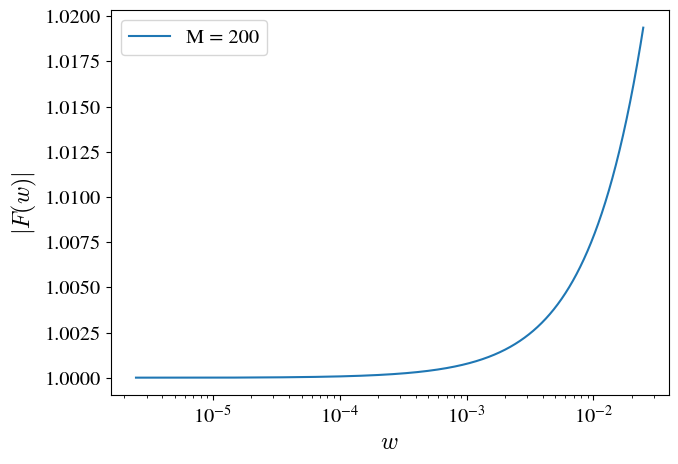

In [1]:
import numpy as np
import h5py
from scipy.interpolate import RectBivariateSpline
import matplotlib.pyplot as plt
from gwlens.lens.point import PML 
from gwlens.tools import plotting


plotting.apply_figure_style()
Msun = 1.988e+30


file = "/work/sreekanth/codes/GWLENS/tests/ansal/interpolation/point.hdf5"
with h5py.File(file, 'r') as file:
    w_values = file['w_values'][:]
    y_values = file['y_values'][:]
    data = file['results'][:]  # (len(w), len(y), 2)

real_data = data[:, :, 0]
imag_data = data[:, :, 1]

real_spline = RectBivariateSpline(w_values,y_values, real_data, kx=3, ky=3)
imag_spline = RectBivariateSpline(w_values, y_values, imag_data, kx=3, ky=3)

frequency_array = np.linspace(0.0001,1,6000)
MLz = 200
y = 3.0


ws = PML.Dimensionless_Frequency(MLz,frequency_array)



F = real_spline(ws,y)[:,0] + 1j*imag_spline(ws,y)[:,0]

plt.plot(ws,np.abs(F),label=f"M = {MLz}")
plt.xlabel("$w$")
plt.ylabel("$|F(w)|$")
plt.xscale("log")
plt.legend()
plt.show()

In [6]:
pml = PML()
Img = pml.solve_images(y1 =0.1, y2=0.6)
Img2= pml.solve_images(y1 =0.1, y2=0, method="numeric")
Img1
print(Img1)
print(Img2)
len(Img)

[{'position': (0.22183430107818125, 1.3310058064690873), 'magnification': 1.4319160035590146, 'type': 'minimum', 'Morse': 0, 'method': 'analytic'}, {'position': (-0.12183430107818122, -0.7310058064690872), 'magnification': -0.43191600355901466, 'type': 'saddle', 'Morse': 1, 'method': 'analytic'}]
[{'position': (1.0512492197250394, 0.0), 'magnification': 5.518730502861166, 'type': 'minimum', 'Morse': 0, 'method': 'numeric'}, {'position': (-0.9512492197250392, 0.0), 'magnification': -4.518730502861161, 'type': 'saddle', 'Morse': 1, 'method': 'numeric'}]


2

In [9]:
mag = []
morse = []
type = []
for i in range(len(Img)):
    mag.append(Img[i]["magnification"])
    morse.append(Img[i]["Morse"])
    type.append(Img[i]["type"])

print(mag,"\n",morse,"\n",type,"\n")

[1.4319160035590146, -0.43191600355901466] 
 [0, 1] 
 ['minimum', 'saddle'] 



In [18]:
len(Img1)

2

Text(0, 0.5, '$|F(w)|$')

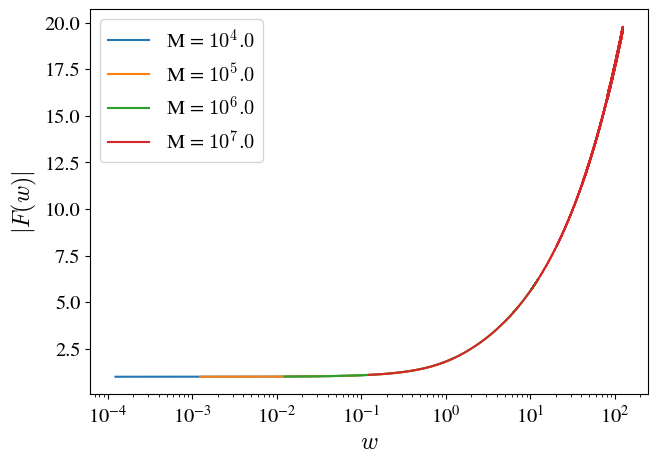

In [ ]:
from gwlens.lens import point
from mpmath import mp
from gwlens.tools import plotting

plotting.apply_figure_style()

mp.dps = 3

pml = point.PML()

f = np.linspace(1e-4,1e-1,4000)
#f = np.linspace(10,100,1000)
mass  = [1e+4,1e+5,1e+6,1e+7]

for m in mass:
    lensmass = m
    w = pml.Dimensionless_Frequency(lensmass,f)


    y = 0.001

    F = []
    for i in w:
        F.append(np.abs(pml.Point(i,y)))

    plt.plot(f,F, label=f"M = $10^{np.log10(m)}$")
plt.legend()
plt.xscale("log")
plt.xlabel("$w$")
plt.ylabel("$|F(w)|$")